# FH Stable


                   Global DE + np.linalg.lstsq Fit Table                    
M11          |      3.54589
M22          |     -0.62126
M33          |      2.24316
M12          |      0.27034
M13          |     -4.50614
M23          |      0.82994
alpha2       |     -0.24579
alpha3       |      0.00424
Na           |   1563.70391
----------------------------------------------------------------------------
Total Chi^2       : 46.838
Degrees of Freedom: 48
Chi^2 / dof       : 0.976

Automated Riemann Sheet Pole Findings:
  [Sheet II (-, +, +) [btt]] W = 3.874765 + i(-0.000485) GeV | M_R = 3874.76 MeV, Width = 0.97 MeV
  [Sheet V (+, -, +) [tbt]] W = 3.854846 + i(-0.000000) GeV | M_R = 3854.85 MeV, Width = 0.00 MeV
  [Sheet VII (-, +, -) [btb]] W = 3.874213 + i(-0.000401) GeV | M_R = 3874.21 MeV, Width = 0.80 MeV


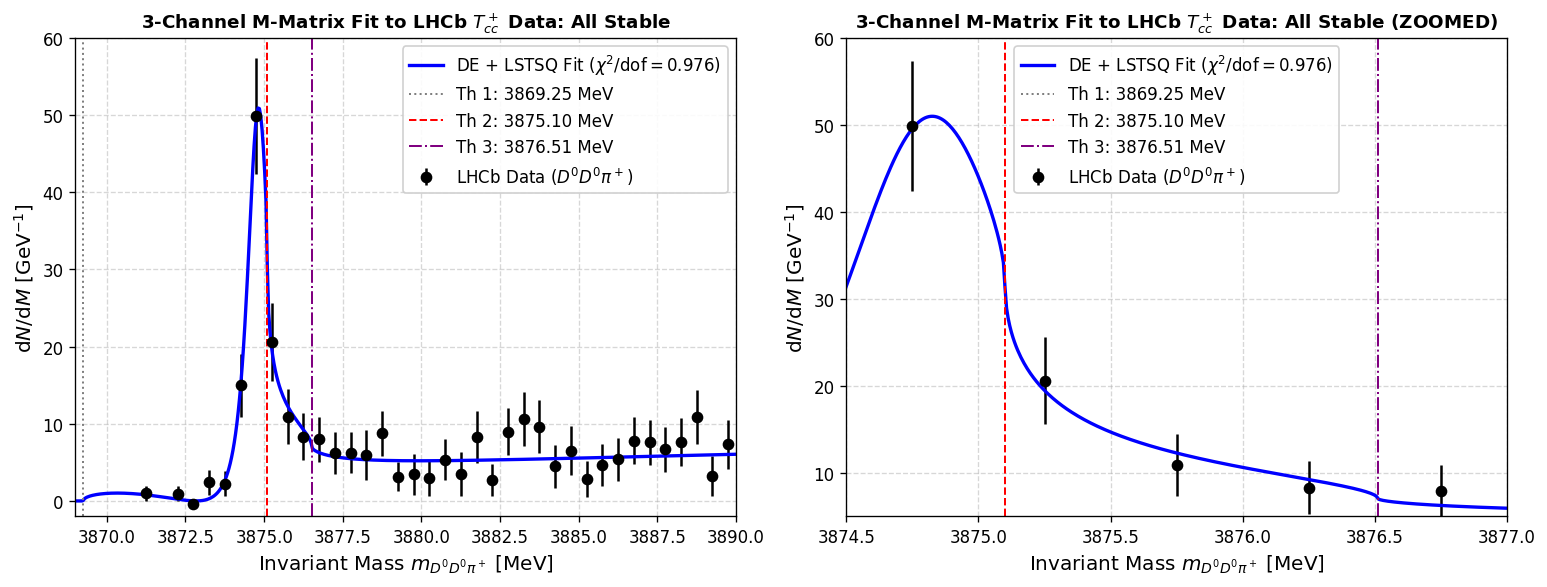

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, root

# ---------------------------------------------------------
# Physical Constants & Thresholds (GeV)
# ---------------------------------------------------------
m_D0 = 1.86484     
m_Dstar = 2.01026  
m_pion = 0.13957   
m_Dstar0 = 2.00685
m_Dplus = 1.86966

M1, m1 = m_D0 + m_pion, m_D0  # Channel 1: (D0 pi+) + D0 (3.86925 GeV)
M2, m2 = m_Dstar, m_D0        # Channel 2: D*+ + D0       (3.87510 GeV)
M3, m3 = m_Dstar0, m_Dplus    # Channel 3: D*0 + D+       (3.87651 GeV)

p_unit = m_pion  # Normalization scale

# ---------------------------------------------------------
# Kinematics & Amplitudes
# ---------------------------------------------------------
def sqrt_rhc(z):
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)
    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def k_cm(s, M, m, sheet_sign=+1):
    s_c = np.asarray(s, dtype=np.complex128) + 1e-12j
    W = np.sqrt(s_c)
    sth = (M + m)**2
    sdiff = (M - m)**2
    z_th = s_c - sth
    z_diff = s_c - sdiff
    return sheet_sign * (sqrt_rhc(z_th) * np.sqrt(z_diff)) / (2.0 * W)

def k1_func(s, sheet_sign=+1): return k_cm(s, M1, m1, sheet_sign=sheet_sign)
def k2_func(s, sheet_sign=+1): return k_cm(s, M2, m2, sheet_sign=sheet_sign)
def k3_func(s, sheet_sign=+1): return k_cm(s, M3, m3, sheet_sign=sheet_sign)

def fh_det_3channel_m_matrix(W_complex, M11, M22, M33, M12, M13, M23, s1=+1, s2=+1, s3=+1):
    s = W_complex**2
    k1 = k1_func(s, sheet_sign=s1) / p_unit
    k2 = k2_func(s, sheet_sign=s2) / p_unit
    k3 = k3_func(s, sheet_sign=s3) / p_unit
    
    z1, z2, z3 = M11 - 1j * k1, M22 - 1j * k2, M33 - 1j * k3
    return z1 * z2 * z3 - z1 * (M23**2) - z2 * (M13**2) - z3 * (M12**2) + 2.0 * M12 * M13 * M23

# ---------------------------------------------------------
# Data & Linear LSTSQ Optimization
# ---------------------------------------------------------
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment='#')
data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

def fit_linear_parameters_lstsq(M_params, E_MeV, y_data=None, y_err=None):
    """Solves for production parameters (Na, alpha2, alpha3) via np.linalg.lstsq on Yield."""
    M11, M22, M33, M12, M13, M23 = M_params
    E_GeV = E_MeV / 1000.0
    s = E_GeV**2
    
    k1 = k1_func(s) / p_unit
    k2 = k2_func(s) / p_unit
    k3 = k3_func(s) / p_unit
    
    z1, z2, z3 = M11 - 1j * k1, M22 - 1j * k2, M33 - 1j * k3
    D = z1 * z2 * z3 - z1 * (M23**2) - z2 * (M13**2) - z3 * (M12**2) + 2.0 * M12 * M13 * M23
    
    T11 = (z2 * z3 - M23**2) / D
    T12 = (M13 * M23 - M12 * z3) / D
    T13 = (M12 * M23 - M13 * z2) / D
    p1 = np.real(k1) * p_unit
    
    if y_data is None:
        return p1, T11, T12, T13

    # Exact yield expansion: Yield = p1 * |c1*T11 + c2*T12 + c3*T13|^2
    # Basis vectors for linear system:
    f11 = np.real(p1) * np.abs(T11)**2
    f22 = np.real(p1) * np.abs(T12)**2
    f33 = np.real(p1) * np.abs(T13)**2
    f12 = np.real(p1) * 2.0 * np.real(T11 * np.conj(T12))
    f13 = np.real(p1) * 2.0 * np.real(T11 * np.conj(T13))
    f23 = np.real(p1) * 2.0 * np.real(T12 * np.conj(T13))
    
    # Solve 6 bilinear cross terms to preserve positive Na:
    A_mat = np.column_stack([f11, f12, f13, f22, f33, f23]) / y_err[:, None]
    b_vec = y_data / y_err
    
    w, _, _, _ = np.linalg.lstsq(A_mat, b_vec, rcond=1e-10)
    
    Na = float(max(w[0], 1e-4))
    alpha2 = float(w[1] / Na)
    alpha3 = float(w[2] / Na)
    
    F1 = T11 + alpha2 * T12 + alpha3 * T13
    yield_pred = Na * p1 * np.abs(F1)**2
    
    chi2 = np.sum(((y_data - yield_pred) / y_err)**2)
    return chi2, Na, alpha2, alpha3, yield_pred

def de_cost_function(M_params):
    chi2, _, _, _, _ = fit_linear_parameters_lstsq(M_params, data_mass_MeV, data_yield, data_err)
    return chi2 if not np.isnan(chi2) else 1e10

m_bounds = [(-5.0, 5.0)] * 6

res_de = differential_evolution(
    de_cost_function,
    bounds=m_bounds,
    seed=42,
    maxiter=1200,
    popsize=20
)

M_opt = res_de.x
chi2_opt, Na_opt, a2_opt, a3_opt, yield_fit = fit_linear_parameters_lstsq(M_opt, data_mass_MeV, data_yield, data_err)

p_opt = {
    'M11': M_opt[0], 'M22': M_opt[1], 'M33': M_opt[2],
    'M12': M_opt[3], 'M13': M_opt[4], 'M23': M_opt[5],
    'alpha2': a2_opt, 'alpha3': a3_opt, 'Na': Na_opt
}

# ---------------------------------------------------------
# 4. Multi-Sheet Pole Search (2D Grid + Cauchy Contour)
# ---------------------------------------------------------
def identify_rs_3channel(s1, s2, s3):
    s1_s = '+' if s1 == +1 else '-'
    s2_s = '+' if s2 == +1 else '-'
    s3_s = '+' if s3 == +1 else '-'
    sheet_code = f"({s1_s}, {s2_s}, {s3_s})"
    sheet_map = {
        (+1, +1, +1): f"Sheet I {sheet_code} [ttt]",
        (-1, +1, +1): f"Sheet II {sheet_code} [btt]",
        (-1, -1, +1): f"Sheet III {sheet_code} [bbt]",
        (-1, -1, -1): f"Sheet IV {sheet_code} [bbb]",
        (+1, -1, +1): f"Sheet V {sheet_code} [tbt]",
        (+1, +1, -1): f"Sheet VI {sheet_code} [ttb]",
        (-1, +1, -1): f"Sheet VII {sheet_code} [btb]",
        (+1, -1, -1): f"Sheet VIII {sheet_code} [tbb]"
    }
    return sheet_map.get((s1, s2, s3), f"Sheet {sheet_code}")

def cauchy_contour_pole_refine(W_center, s1, s2, s3, r=2e-4, n_pts=64):
    angles = np.linspace(0, 2 * np.pi, n_pts, endpoint=False)
    circle = W_center + r * np.exp(1j * angles)
    dW = 1j * r * np.exp(1j * angles) * (2 * np.pi / n_pts)
    
    D_vals = fh_det_3channel_m_matrix(circle, *M_opt, s1=s1, s2=s2, s3=s3)
    I_num = np.sum((circle / D_vals) * dW)
    I_den = np.sum((1.0 / D_vals) * dW)
    return I_num / I_den if abs(I_den) > 1e-4 else W_center

def auto_search_all_sheets(M_params):
    sheets = [
        (+1, +1, +1), (-1, +1, +1), (-1, -1, +1), (-1, -1, -1),
        (+1, -1, +1), (+1, +1, -1), (-1, +1, -1), (+1, -1, -1)
    ]
    
    # Expanded grid search bounds (GeV): covers real mass 3.860-3.890 and width up to 100 MeV
    E_re = np.linspace(3.860, 3.890, 1000) # 150 x 150 grid search
    E_im = np.linspace(-0.050, 0.002, 1000)
    grid_R, grid_I = np.meshgrid(E_re, E_im)
    W_grid = grid_R + 1j * grid_I
    
    all_poles = []
    
    for (s1, s2, s3) in sheets:
        det_grid = np.abs(fh_det_3channel_m_matrix(W_grid, *M_params, s1=s1, s2=s2, s3=s3))
        # Find local minima across 2D grid
        """
        np.roll(det_grid, 1, axis=0): Shifts down by 1 row. Thus checks if a cell is smaller than its top neighbor.
        np.roll(det_grid, -1, axis=0): Shifts up by 1 row. if a cell is smaller than its bottom neighbor.
        np.roll(det_grid, 1, axis=1): Shifts right by 1 column. if a cell is smaller than its left neighbor.
        np.roll(det_grid, -1, axis=1): Shifts left by 1 column. if a cell is smaller than its right neighbor.
        """
        min_mask = (det_grid < np.roll(det_grid, 1, axis=0)) & \
                   (det_grid < np.roll(det_grid, -1, axis=0)) & \
                   (det_grid < np.roll(det_grid, 1, axis=1)) & \
                   (det_grid < np.roll(det_grid, -1, axis=1))
        
        min_indices = np.argwhere(min_mask)
        
        for idx in min_indices:
            W_seed = W_grid[tuple(idx)]
            if det_grid[tuple(idx)] < 5.0:  # Candidate root threshold
                W_cauchy = cauchy_contour_pole_refine(W_seed, s1, s2, s3)
                def det_func(x):
                    val = fh_det_3channel_m_matrix(x[0] + 1j * x[1], *M_params, s1=s1, s2=s2, s3=s3)
                    return [val.real, val.imag]
                    
                sol = root(det_func, [W_cauchy.real, W_cauchy.imag], method='hybr')
                if sol.success:
                    W_pole = sol.x[0] + 1j * sol.x[1]
                    res = abs(fh_det_3channel_m_matrix(W_pole, *M_params, s1=s1, s2=s2, s3=s3))
                    if res < 1e-5 and 3.85 <= W_pole.real <= 3.90 and -0.1 <= W_pole.imag <= 0.0:
                        sheet_label = identify_rs_3channel(s1, s2, s3)
                        if not any(np.isclose(W_pole, p['W'], atol=1e-4) for p in all_poles): # Remove Dupes
                            all_poles.append({
                                'W': W_pole,
                                'sheet': sheet_label,
                                's1': s1, 's2': s2, 's3': s3
                            })
                            
    return all_poles

poles_found = auto_search_all_sheets(M_opt)

# ---------------------------------------------------------
# 5. Output Summary & Plotting
# ---------------------------------------------------------
dof = len(data_yield) - 9
chi2_dof = chi2_opt / dof

print("=" * 76)
print(f"{'Global DE + np.linalg.lstsq Fit Table':^76}")
print("=" * 76)
for name, val in p_opt.items():
    print(f"{name:<12} | {val:12.5f}")
print("-" * 76)
print(f"Total Chi^2       : {chi2_opt:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 76)

print("\nAutomated Riemann Sheet Pole Findings:")
if len(poles_found) == 0:
    print("  No poles detected within search boundary.")
else:
    for p in poles_found:
        W_p = p['W']
        M_R = W_p.real * 1000.0
        Gamma_R = -2.0 * W_p.imag * 1000.0
        print(f"  [{p['sheet']}] W = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV | M_R = {M_R:.2f} MeV, Width = {Gamma_R:.2f} MeV")
print("=" * 76)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (M2 + m2) * 1000.0
m_th3 = (M3 + m3) * 1000.0

# Fig (a)
E_fine_MeV = np.linspace(3869.0, 3890.0, 500)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(M_opt, E_fine_MeV)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fine = Na_opt * p1_f * np.abs(F1_f)**2
ax[0].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt='o', color='black', label=r'LHCb Data ($D^0 D^0 \pi^+$)')
ax[0].plot(E_fine_MeV, yield_fine, color='blue', lw=2, label=f'DE + LSTSQ Fit ($\\chi^2/\\mathrm{{dof}} = {chi2_dof:.3f}$)')
ax[0].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=f'Th 1: {m_th1:.2f} MeV')
ax[0].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=f'Th 2: {m_th2:.2f} MeV')
ax[0].axvline(m_th3, color='purple', linestyle='-.', lw=1.2, label=f'Th 3: {m_th3:.2f} MeV')
ax[0].set_title(r'3-Channel M-Matrix Fit to LHCb $T_{cc}^+$ Data: All Stable', fontsize=11, fontweight='bold')
ax[0].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[0].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Fig (b)
E_fine_MeV_ZOOM = np.linspace(3874.0, 3877.0, 500)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(M_opt, E_fine_MeV_ZOOM)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fine_ZOOM = Na_opt * p1_f * np.abs(F1_f)**2
ax[1].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt='o', color='black', label=r'LHCb Data ($D^0 D^0 \pi^+$)')
ax[1].plot(E_fine_MeV_ZOOM, yield_fine_ZOOM, color='blue', lw=2, label=f'DE + LSTSQ Fit ($\\chi^2/\\mathrm{{dof}} = {chi2_dof:.3f}$)')
ax[1].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=f'Th 1: {m_th1:.2f} MeV')
ax[1].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=f'Th 2: {m_th2:.2f} MeV')
ax[1].axvline(m_th3, color='purple', linestyle='-.', lw=1.2, label=f'Th 3: {m_th3:.2f} MeV')
ax[1].set_title(r'3-Channel M-Matrix Fit to LHCb $T_{cc}^+$ Data: All Stable (ZOOMED)', fontsize=11, fontweight='bold')
ax[1].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[1].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[1].set_xlim(3874.5, 3877.0)
ax[1].set_ylim(5, 60)
ax[1].grid(True, linestyle='--', alpha=0.5)
ax[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

# FH Unstable

                   Global DE + np.linalg.lstsq Fit Table                    
M11          |     -4.45287
M22          |      0.57902
M33          |     -0.58838
M12          |      0.42120
M13          |      0.93807
M23          |     -0.27628
alpha2       |     -0.03113
alpha3       |     -0.05939
Na           |    670.27948
----------------------------------------------------------------------------
Total Chi^2       : 47.863
Degrees of Freedom: 48
Chi^2 / dof       : 0.997

Automated Riemann Sheet Pole Findings:
  [Sheet II (-, +, +) [btt]] W = 3.870849 + i(-0.000060) GeV | M_R = 3870.85 MeV, Width = 0.12 MeV
  [Sheet II (-, +, +) [btt]] W = 3.874582 + i(0.000276) GeV | M_R = 3874.58 MeV, Width = -0.55 MeV
  [Sheet III (-, -, +) [bbt]] W = 3.874177 + i(0.000929) GeV | M_R = 3874.18 MeV, Width = -1.86 MeV
  [Sheet V (+, -, +) [tbt]] W = 3.872764 + i(0.000714) GeV | M_R = 3872.76 MeV, Width = -1.43 MeV
  [Sheet VI (+, +, -) [ttb]] W = 3.874157 + i(-0.000984) GeV | M_R = 3874.16 MeV, 

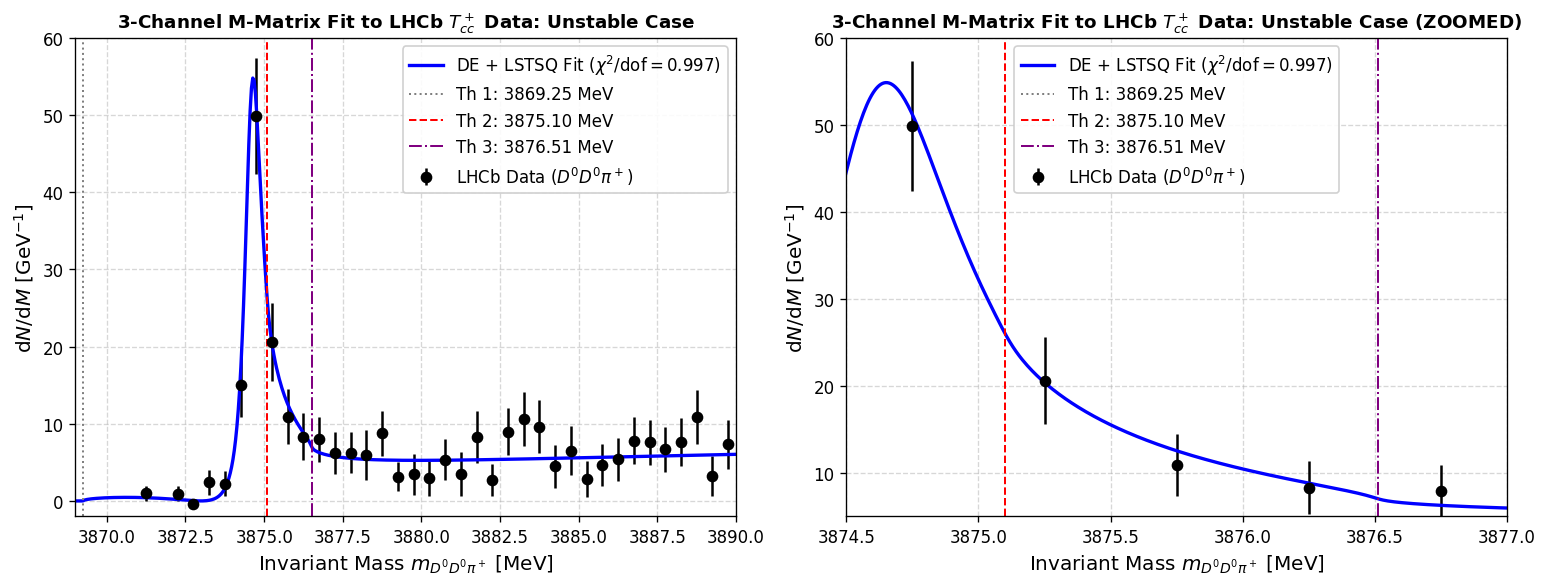

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, root

# ---------------------------------------------------------
# 1. Physical Constants & Isobar Channel Thresholds (GeV)
# ---------------------------------------------------------
m_D0 = 1.86484     
m_Dstar = 2.01026  
m_pion = 0.13957   
m_Dstar0 = 2.00685
m_Dplus = 1.86966

Gamma_Dstar_plus = 0.0000834  # D*+ total width ~ 83.4 keV (0.0834 MeV)
Gamma_Dstar_0 = 0.0000559  # D*0 total width ~ 55.9 keV (0.0559 MeV)

# Isobar channel thresholds
M1, m1 = m_D0 + m_pion, m_D0  # Channel 1: (D0 pi+) + D0 (3.86925 GeV)
M2, m2 = m_Dstar, m_D0        # Channel 2: D*+ + D0        (3.87510 GeV)
M3, m3 = m_Dstar0, m_Dplus    # Channel 3: D*0 + D+        (3.87651 GeV)

# Momentum normalization unit (m_pion) for dimensionless parameters
p_unit = m_pion  

# ---------------------------------------------------------
# 2. Kinematics & Momentum Functions
# ---------------------------------------------------------
def k1_func(s, sheet_sign=+1):
    """Center-of-mass momentum for Channel 1."""
    W = np.sqrt(s + 0j)
    s_th = (M1 + m1)**2
    s_lambda = (s - s_th) * (s - (M1 - m1)**2 + 0j)
    return sheet_sign * np.sqrt(s_lambda) / (2.0 * W)

def k2_func_stable(s, sheet_sign=+1):
    """Center-of-mass momentum for Channel 2."""
    W = np.sqrt(s + 0j)
    s_th = (M2 + m2)**2
    s_lambda = (s - s_th) * (s - (M2 - m2)**2 + 0j)
    return sheet_sign * np.sqrt(s_lambda) / (2.0 * W)

def k2_func_unstable(s, width=Gamma_Dstar_plus, sheet_sign=+1):
    """Channel 2 momentum for UNSTABLE D*+ (complex mass m_Dstar - i * Gamma / 2)."""
    W = np.sqrt(s + 0j)
    s_th = (M2 - 0.5j * width + m2)**2
    s_lambda = (s - s_th) * (s - (M2 - m2)**2 + 0j)
    return sheet_sign * np.sqrt(s_lambda) / (2.0 * W)

def k3_func_stable(s, sheet_sign=+1):
    """Center-of-mass momentum for Channel 3."""
    W = np.sqrt(s + 0j)
    s_th = (M3 + m3)**2
    s_lambda = (s - s_th) * (s - (M3 - m3)**2 + 0j)
    return sheet_sign * np.sqrt(s_lambda) / (2.0 * W)

def k3_func_unstable(s, width=Gamma_Dstar_0, sheet_sign=+1):
    """Channel 3 momentum for UNSTABLE D*0 (complex mass m_Dstar - i * Gamma / 2)."""
    W = np.sqrt(s + 0j)
    s_th = (M3 - 0.5j * width + m3)**2
    s_lambda = (s - s_th) * (s - (M3 - m3)**2 + 0j)
    return sheet_sign * np.sqrt(s_lambda) / (2.0 * W)

# def k3_func_unstable(s, width=Gamma_Dstar_0, sheet_sign=+1):
#     """Channel 3 momentum for UNSTABLE D*0 (complex mass m_Dstar - i * Gamma / 2)."""
#     W = np.sqrt(s + 0j)
#     m3_comp = m3 - 1j * (width / 2.0)
#     s_th = (M3 + m3_comp)**2
#     k2_sq = (s - s_th) * (s - (M3 - m3_comp)**2) / (2.0 * W)
#     delta = (2.0 * M3 * m3 / (M3 + m3)) * (width / 2.0)
#     return sheet_sign * np.sqrt(k2_sq + 1j * delta)
    

def fh_det_3channel_m_matrix(W_complex, M11, M22, M33, M12, M13, M23, s1=+1, s2=+1, s3=+1):
    s = W_complex**2
    k1 = k1_func(s, sheet_sign=s1) / p_unit
    k2 = k2_func_unstable(s, sheet_sign=s2) / p_unit
    k3 = k3_func_unstable(s, sheet_sign=s3) / p_unit
    
    z1, z2, z3 = M11 - 1j * k1, M22 - 1j * k2, M33 - 1j * k3
    return z1 * z2 * z3 - z1 * (M23**2) - z2 * (M13**2) - z3 * (M12**2) + 2.0 * M12 * M13 * M23

# ---------------------------------------------------------
# 3. Data & Linear LSTSQ Optimization
# ---------------------------------------------------------
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment='#')
data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

def fit_linear_parameters_lstsq(M_params, E_MeV, y_data=None, y_err=None):
    """Solves for production parameters (Na, alpha2, alpha3) via np.linalg.lstsq on Yield."""
    M11, M22, M33, M12, M13, M23 = M_params
    E_GeV = E_MeV / 1000.0
    s = E_GeV**2
    
    k1 = k1_func(s) / p_unit
    k2 = k2_func_unstable(s) / p_unit
    k3 = k3_func_unstable(s) / p_unit
    
    z1, z2, z3 = M11 - 1j * k1, M22 - 1j * k2, M33 - 1j * k3
    D = z1 * z2 * z3 - z1 * (M23**2) - z2 * (M13**2) - z3 * (M12**2) + 2.0 * M12 * M13 * M23
    
    T11 = (z2 * z3 - M23**2) / D
    T12 = (M13 * M23 - M12 * z3) / D
    T13 = (M12 * M23 - M13 * z2) / D
    p1 = np.real(k1) * p_unit
    
    if y_data is None:
        return p1, T11, T12, T13

    # Exact yield expansion: Yield = p1 * |c1*T11 + c2*T12 + c3*T13|^2
    # Basis vectors for linear system:
    f11 = p1 * np.abs(T11)**2
    f22 = p1 * np.abs(T12)**2
    f33 = p1 * np.abs(T13)**2
    f12 = p1 * 2.0 * np.real(T11 * np.conj(T12))
    f13 = p1 * 2.0 * np.real(T11 * np.conj(T13))
    f23 = p1 * 2.0 * np.real(T12 * np.conj(T13))
    
    # Solve 6 bilinear cross terms to preserve positive Na:
    A_mat = np.column_stack([f11, f12, f13, f22, f33, f23]) / y_err[:, None]
    b_vec = y_data / y_err
    
    w, _, _, _ = np.linalg.lstsq(A_mat, b_vec, rcond=1e-10)
    
    Na = max(w[0], 1e-4)
    alpha2 = w[1] / Na
    alpha3 = w[2] / Na
    
    F1 = T11 + alpha2 * T12 + alpha3 * T13
    yield_pred = Na * p1 * np.abs(F1)**2
    
    chi2 = np.sum(((y_data - yield_pred) / y_err)**2)
    return chi2, Na, alpha2, alpha3, yield_pred

def de_cost_function(M_params):
    chi2, _, _, _, _ = fit_linear_parameters_lstsq(M_params, data_mass_MeV, data_yield, data_err)
    return chi2 if not np.isnan(chi2) else 1e10

m_bounds = [(-5.0, 5.0)] * 6

res_de = differential_evolution(
    de_cost_function,
    bounds=m_bounds,
    seed=42,
    maxiter=1200,
    popsize=20
)

M_opt = res_de.x
chi2_opt, Na_opt, a2_opt, a3_opt, yield_fit = fit_linear_parameters_lstsq(M_opt, data_mass_MeV, data_yield, data_err)

p_opt = {
    'M11': M_opt[0], 'M22': M_opt[1], 'M33': M_opt[2],
    'M12': M_opt[3], 'M13': M_opt[4], 'M23': M_opt[5],
    'alpha2': a2_opt, 'alpha3': a3_opt, 'Na': Na_opt
}

# ---------------------------------------------------------
# 4. Multi-Sheet Pole Search (2D Grid + Cauchy Contour)
# ---------------------------------------------------------
def identify_rs_3channel(s1, s2, s3):
    s1_s = '+' if s1 == +1 else '-'
    s2_s = '+' if s2 == +1 else '-'
    s3_s = '+' if s3 == +1 else '-'
    sheet_code = f"({s1_s}, {s2_s}, {s3_s})"
    sheet_map = {
        (+1, +1, +1): f"Sheet I {sheet_code} [ttt]",
        (-1, +1, +1): f"Sheet II {sheet_code} [btt]",
        (-1, -1, +1): f"Sheet III {sheet_code} [bbt]",
        (-1, -1, -1): f"Sheet IV {sheet_code} [bbb]",
        (+1, -1, +1): f"Sheet V {sheet_code} [tbt]",
        (+1, +1, -1): f"Sheet VI {sheet_code} [ttb]",
        (-1, +1, -1): f"Sheet VII {sheet_code} [btb]",
        (+1, -1, -1): f"Sheet VIII {sheet_code} [tbb]"
    }
    return sheet_map.get((s1, s2, s3), f"Sheet {sheet_code}")

def cauchy_contour_pole_refine(W_center, s1, s2, s3, r=2e-4, n_pts=64):
    angles = np.linspace(0, 2 * np.pi, n_pts, endpoint=False)
    circle = W_center + r * np.exp(1j * angles)
    dW = 1j * r * np.exp(1j * angles) * (2 * np.pi / n_pts)
    
    D_vals = fh_det_3channel_m_matrix(circle, *M_opt, s1=s1, s2=s2, s3=s3)
    I_num = np.sum((circle / D_vals) * dW)
    I_den = np.sum((1.0 / D_vals) * dW)
    return I_num / I_den if abs(I_den) > 1e-4 else W_center

def auto_search_all_sheets(M_params):
    sheets = [
        (+1, +1, +1), (-1, +1, +1), (-1, -1, +1), (-1, -1, -1),
        (+1, -1, +1), (+1, +1, -1), (-1, +1, -1), (+1, -1, -1)
    ]
    
    # Expanded grid search bounds (GeV): covers real mass 3.860-3.890 and width up to 100 MeV
    E_re = np.linspace(3.860, 3.890, 1000)
    E_im = np.linspace(-0.050, 0.002, 1000)
    grid_R, grid_I = np.meshgrid(E_re, E_im)
    W_grid = grid_R + 1j * grid_I
    
    all_poles = []
    
    for (s1, s2, s3) in sheets:
        det_grid = np.abs(fh_det_3channel_m_matrix(W_grid, *M_params, s1=s1, s2=s2, s3=s3))
        
        # Find local minima across 2D grid
        min_mask = (det_grid < np.roll(det_grid, 1, axis=0)) & \
                   (det_grid < np.roll(det_grid, -1, axis=0)) & \
                   (det_grid < np.roll(det_grid, 1, axis=1)) & \
                   (det_grid < np.roll(det_grid, -1, axis=1))
        
        min_indices = np.argwhere(min_mask)
        
        for idx in min_indices:
            W_seed = W_grid[tuple(idx)]
            
            if det_grid[tuple(idx)] < 5.0:  # Candidate root threshold
                W_cauchy = cauchy_contour_pole_refine(W_seed, s1, s2, s3)
                
                def det_func(x):
                    val = fh_det_3channel_m_matrix(x[0] + 1j * x[1], *M_params, s1=s1, s2=s2, s3=s3)
                    return [val.real, val.imag]
                    
                sol = root(det_func, [W_cauchy.real, W_cauchy.imag], method='hybr')
                if sol.success:
                    W_pole = sol.x[0] + 1j * sol.x[1]
                    res = abs(fh_det_3channel_m_matrix(W_pole, *M_params, s1=s1, s2=s2, s3=s3))
                    
                    if res < 1e-5 and 3.85 <= W_pole.real <= 3.90 and -0.1 <= W_pole.imag <= 0.005:
                        sheet_label = identify_rs_3channel(s1, s2, s3)
                        if not any(np.isclose(W_pole, p['W'], atol=1e-4) for p in all_poles):
                            all_poles.append({
                                'W': W_pole,
                                'sheet': sheet_label,
                                's1': s1, 's2': s2, 's3': s3
                            })
                            
    return all_poles

poles_found = auto_search_all_sheets(M_opt)

# ---------------------------------------------------------
# 5. Output Summary & Plotting
# ---------------------------------------------------------
dof = len(data_yield) - 9
chi2_dof = chi2_opt / dof

print("=" * 76)
print(f"{'Global DE + np.linalg.lstsq Fit Table':^76}")
print("=" * 76)
for name, val in p_opt.items():
    print(f"{name:<12} | {val:12.5f}")
print("-" * 76)
print(f"Total Chi^2       : {chi2_opt:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 76)

print("\nAutomated Riemann Sheet Pole Findings:")
if len(poles_found) == 0:
    print("  No poles detected within search boundary.")
else:
    for p in poles_found:
        W_p = p['W']
        M_R = W_p.real * 1000.0
        Gamma_R = -2.0 * W_p.imag * 1000.0
        print(f"  [{p['sheet']}] W = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV | M_R = {M_R:.2f} MeV, Width = {Gamma_R:.2f} MeV")
print("=" * 76)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (M2 + m2) * 1000.0
m_th3 = (M3 + m3) * 1000.0

# Fig (a)
E_fine_MeV = np.linspace(3869.0, 3890.0, 500)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(M_opt, E_fine_MeV)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fine = Na_opt * p1_f * np.abs(F1_f)**2
ax[0].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt='o', color='black', label=r'LHCb Data ($D^0 D^0 \pi^+$)')
ax[0].plot(E_fine_MeV, yield_fine, color='blue', lw=2, label=f'DE + LSTSQ Fit ($\\chi^2/\\mathrm{{dof}} = {chi2_dof:.3f}$)')
ax[0].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=f'Th 1: {m_th1:.2f} MeV')
ax[0].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=f'Th 2: {m_th2:.2f} MeV')
ax[0].axvline(m_th3, color='purple', linestyle='-.', lw=1.2, label=f'Th 3: {m_th3:.2f} MeV')
ax[0].set_title(r'3-Channel M-Matrix Fit to LHCb $T_{cc}^+$ Data: Unstable Case', fontsize=11, fontweight='bold')
ax[0].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[0].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Fig (b)
E_fine_MeV_ZOOM = np.linspace(3874.0, 3877.0, 500)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(M_opt, E_fine_MeV_ZOOM)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fine_ZOOM = Na_opt * p1_f * np.abs(F1_f)**2
ax[1].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt='o', color='black', label=r'LHCb Data ($D^0 D^0 \pi^+$)')
ax[1].plot(E_fine_MeV_ZOOM, yield_fine_ZOOM, color='blue', lw=2, label=f'DE + LSTSQ Fit ($\\chi^2/\\mathrm{{dof}} = {chi2_dof:.3f}$)')
ax[1].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=f'Th 1: {m_th1:.2f} MeV')
ax[1].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=f'Th 2: {m_th2:.2f} MeV')
ax[1].axvline(m_th3, color='purple', linestyle='-.', lw=1.2, label=f'Th 3: {m_th3:.2f} MeV')
ax[1].set_title(r'3-Channel M-Matrix Fit to LHCb $T_{cc}^+$ Data: Unstable Case (ZOOMED)', fontsize=11, fontweight='bold')
ax[1].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[1].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[1].set_xlim(3874.5, 3877.0)
ax[1].set_ylim(5, 60)
ax[1].grid(True, linestyle='--', alpha=0.5)
ax[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()